In [59]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.multivariate.factor import Factor
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from sklearn.cluster import KMeans


In [60]:
df = pd.read_excel("DATA.xlsx")

In [61]:
df.head()

,Регионы,"Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной горячим водоснабжением, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной отоплением, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной водоотведением (канализацией), в общей площади всего жилищного фонда (процент, значение показателя за год)",Количество построенных квартир на 1000 чел. (значение показателя за год),Введено в действие общей площади жилых домов на 1000 чел. (тысяча квадратных метров общей площади)
0,Белгородская область,90.08,80.98,99.64,84.90,5.875466,0.551034
1,Брянская область,83.72,70.86,92.97,77.97,4.194826,0.419396
2,Владимирская область,86.02,64.18,87.73,78.57,9.126813,0.886967
3,Воронежская область,85.67,79.02,90.14,82.40,10.789691,0.837769
4,Ивановская область,74.38,65.49,85.26,72.02,3.751278,0.426791


In [62]:
df.columns = ["regions", "x1", "x2", "x3", "x4", "x5", "x6"]

In [63]:
new_df = df.set_index("regions")

In [64]:
ylabels = ["%", "%", "%", "%", "квартир на 1000 чел.", "тыс. кв. м."]
i = 0

for column in new_df.columns:
    plt.figure(figsize = (12, 4))
    new_df.boxplot(column = [column])
    plt.ylabel(ylabels[i])
    plt.savefig(f"boxplots/{i}s.png")
    plt.close()
    i += 1

In [65]:
corr = new_df.corr().round(3)
corr.style.background_gradient()

,x1,x2,x3,x4,x5,x6
x1,1.000000,0.869000,0.731000,0.958000,0.195000,0.199000
x2,0.869000,1.000000,0.799000,0.929000,0.174000,0.137000
x3,0.731000,0.799000,1.000000,0.754000,0.088000,0.087000
x4,0.958000,0.929000,0.754000,1.000000,0.240000,0.213000
x5,0.195000,0.174000,0.088000,0.240000,1.000000,0.927000
x6,0.199000,0.137000,0.087000,0.213000,0.927000,1.000000


In [66]:
qrs = []
maxes = []
mines = []
desc_stat = new_df.describe()
desc_stat = desc_stat.T

for column in new_df.columns:
    qrs.append(count_iqr(new_df[column].values))
    maxes.append(new_df[new_df[column] == new_df[column].max()].index[0])
    mines.append(new_df[new_df[column] == new_df[column].min()].index[0])

desc_stat["iqr"] = qrs
desc_stat["spread"] = desc_stat["max"] - desc_stat["min"]
desc_stat["min_region"] = mines
desc_stat["max_region"] = maxes

desc_stat.round(1)

,count,mean,std,min,25%,50%,75%,max,iqr,spread,min_region,max_region
x1,82.0,82.3,11.9,41.8,77.9,84.9,90.4,99.9,12.6,58.0,Республика Тыва,Республика Северная Осетия-Алания
x2,82.0,70.0,14.0,39.9,60.0,70.4,78.9,98.2,18.9,58.3,Республика Алтай,Республика Северная Осетия-Алания
x3,82.0,85.8,10.9,55.7,78.8,88.7,95.4,99.6,16.6,43.9,Республика Бурятия,Белгородская область
x4,82.0,77.1,12.4,34.2,70.3,78.6,85.7,98.8,15.4,64.6,Республика Тыва,Республика Северная Осетия-Алания
x5,82.0,7.2,3.9,1.2,4.7,6.6,8.5,25.9,3.7,24.7,Чукотский автономный округ,Ленинградская область
x6,82.0,0.6,0.3,0.1,0.4,0.6,0.7,2.0,0.3,1.9,Чукотский автономный округ,Ленинградская область


In [67]:
desc_stat.to_excel("descript_stat.xlsx")

In [68]:
corr.to_excel("correlation.xlsx")

In [69]:
std_df = new_df.copy()

for col in std_df.columns:
    std_df[col] = (std_df[col] - std_df[col].mean()) / std_df[col].std()

In [70]:
chi_square_value, p_value = calculate_bartlett_sphericity(std_df)
chi_square_value, p_value

(602.3286877349395, 1.1363739507781915e-118)

In [71]:
kmo_all, kmo_model = calculate_kmo(std_df)
kmo_model

0.6923457650425529

In [72]:
fa = Factor(std_df, n_factor = 6, method = "pa")
res = fa.fit()

In [73]:
res.rotate(method = "varimax")
res.get_loadings_frame(threshold=0)

,factor 0,factor 1,factor 2,factor 3,factor 4
x4,0.987065,-0.139506,-0.071537,0.032246,-0.017826
x1,0.952575,-0.111773,-0.094062,-0.145326,0.016354
x2,0.944074,-0.069830,0.227892,0.118049,0.006936
x3,0.784503,-0.013860,0.283053,-0.061168,-0.003634
x5,0.104164,-0.963491,-0.006800,0.085810,0.011747
x6,0.083616,-0.961460,0.008634,-0.089153,-0.011929


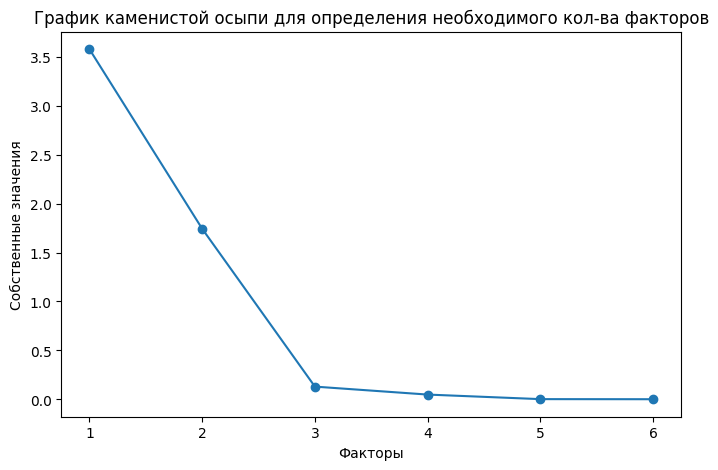

In [74]:
plt.close()

plt.figure(figsize=(8, 5))
plt.scatter(range(1,std_df.shape[1]+1), res.eigenvals)
plt.plot(range(1,std_df.shape[1]+1), res.eigenvals)
plt.title('График каменистой осыпи для определения необходимого кол-ва факторов')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')

plt.savefig("stones_scree.png")

In [75]:
load = res.loadings.T[:2].T
pces = np.dot(std_df, load)
pc1 = []
pc2 = []

for i in pces:
    print
    pc1.append(i[0])
    pc2.append(i[1])

data = {"regions": std_df.index, "f1": pc1, "f2": pc2}

integral_char = pd.DataFrame(data)
integral_char = integral_char.set_index("regions")

In [76]:
sk_ac = AgglomerativeClustering(n_clusters=4, linkage='ward')
sk_ac_pred_res = sk_ac.fit_predict(integral_char)

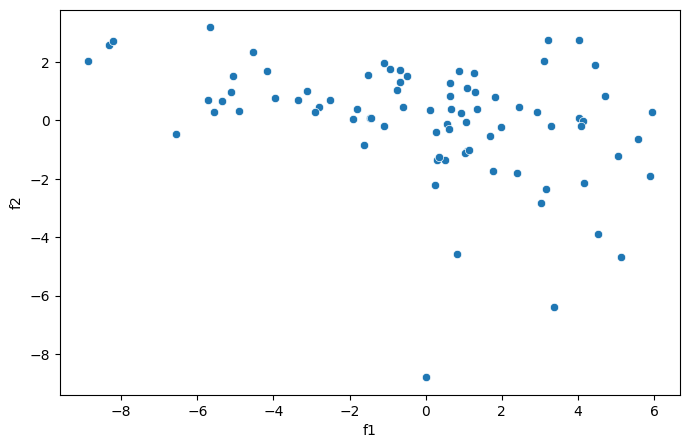

In [77]:
plt.close()

plt.figure(figsize=(8, 5))

sns.scatterplot(data = integral_char, x = "f1", y = "f2")

plt.savefig("ward_scatter.png")

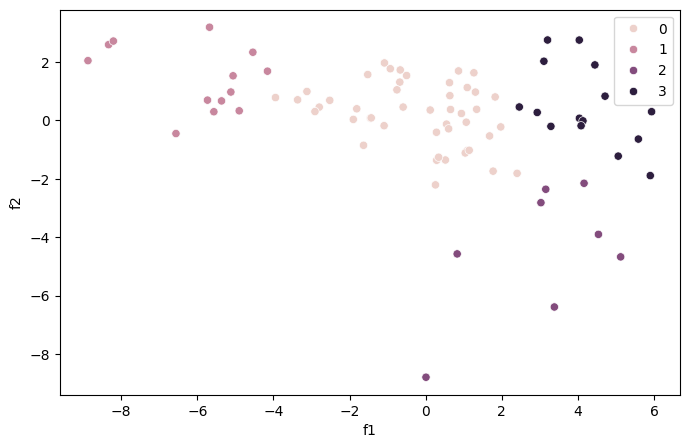

In [78]:
plt.close()

plt.figure(figsize=(8, 5))

sns.scatterplot(data = integral_char, x = "f1", y = "f2", hue = sk_ac_pred_res)

plt.savefig("ward_scatter_clusters.png")

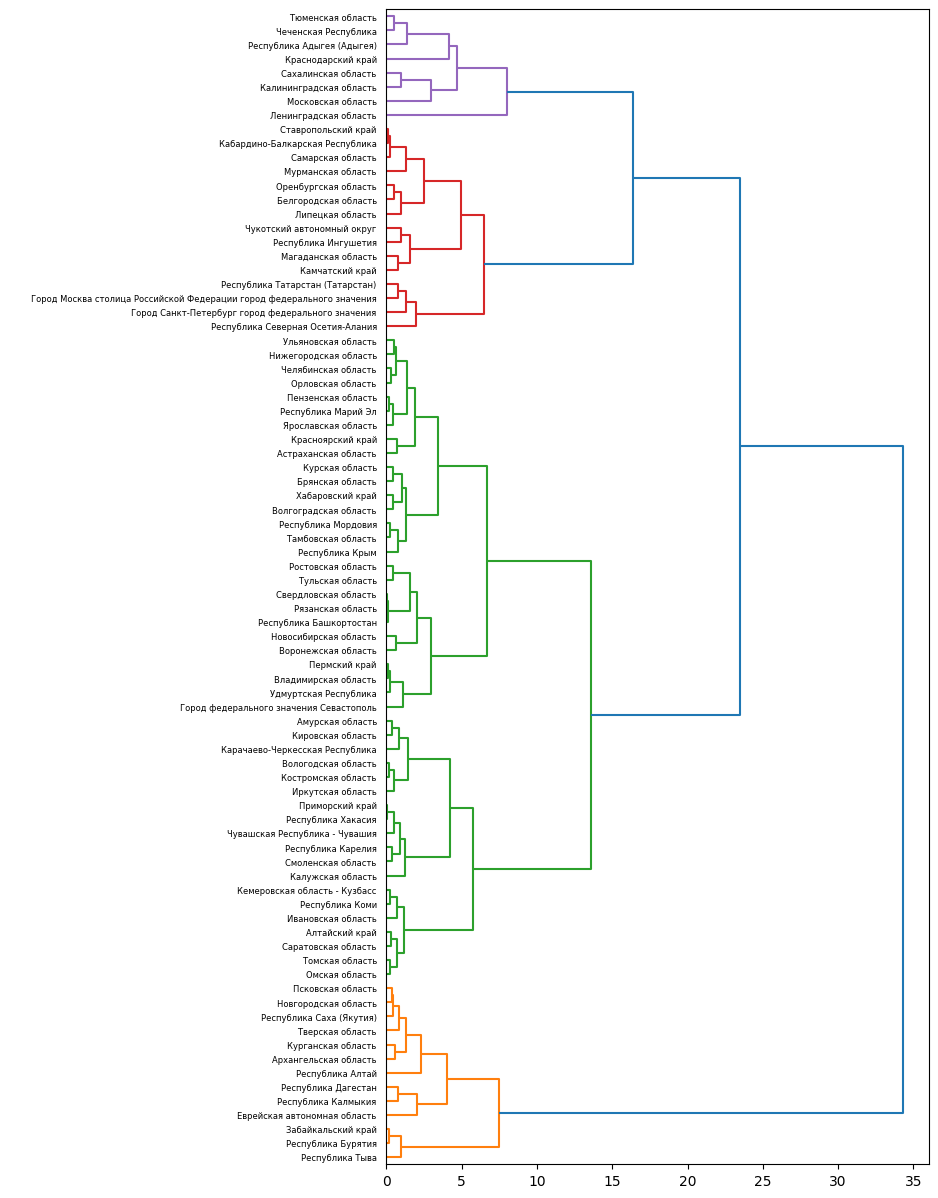

In [79]:
Z = linkage(integral_char, method='ward', metric='euclidean')

plt.close()
plt.figure(figsize=(7, 15))
dendrogram(Z, color_threshold=15, orientation="right", labels = integral_char.index)
plt.savefig("ward_dendro.png")

In [80]:
integral_char["class"] = sk_ac_pred_res
integral_char.to_excel("ward_clusters.xlsx")

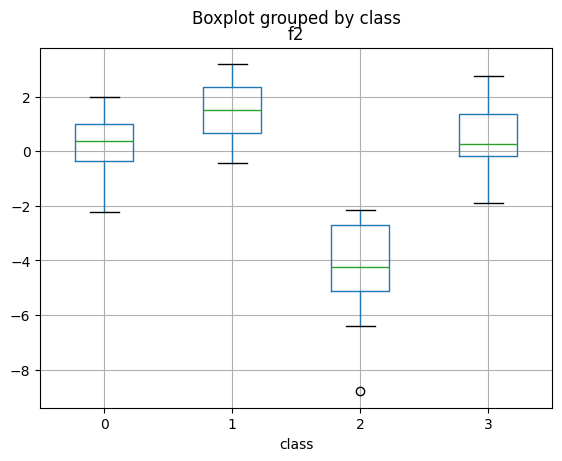

In [81]:
plt.close()
integral_char.boxplot(column="f1", by = "class")
plt.savefig("boxplots/ward_pc1_clust_boxs.png")

plt.close()
integral_char.boxplot(column="f2", by = "class")
plt.savefig("boxplots/ward_pc2_clust_boxs.png")

In [82]:
kmeans = KMeans(n_clusters=4)
k_means_predict = kmeans.fit_predict(integral_char)

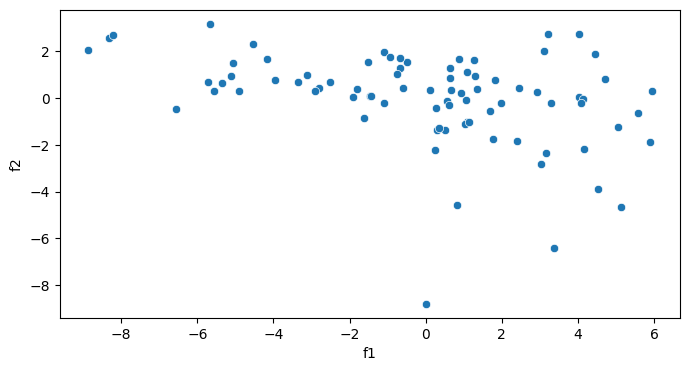

In [83]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "f1", y = "f2")
plt.savefig("kmeans_scatter.png")

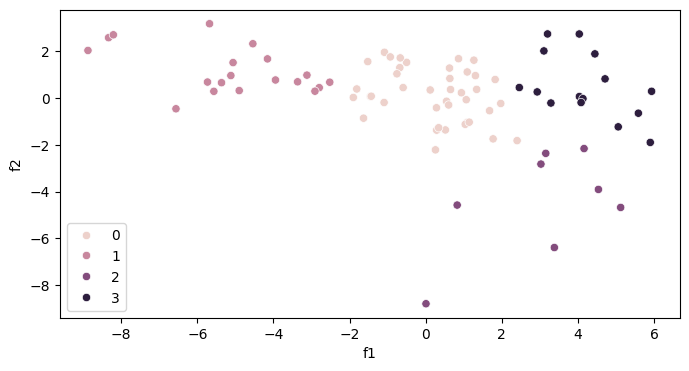

In [84]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "f1", y = "f2", hue = k_means_predict)
plt.savefig("kmeans_scatter_clusters.png")

In [85]:
integral_char["class"] = k_means_predict
integral_char.to_excel("kmeans_clusters.xlsx")


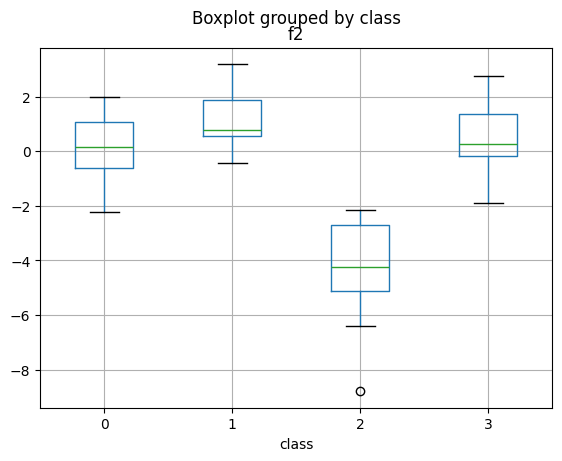

In [86]:
plt.close()
integral_char.boxplot(column="f1", by = "class")
plt.savefig("boxplots/kmeans_pc1_clust_boxs.png")

plt.close()
integral_char.boxplot(column="f2", by = "class")
plt.savefig("boxplots/kmeans_pc2_clust_boxs.png")